# Two-Asset Portfolios: Why Correlation Matters

In this notebook, we will study how two assets can be combined into a portfolio and, especially, how **correlation changes portfolio risk**.

The central question is:

> **What happens to portfolio risk when correlation changes, while the individual assets remain the same?**

### Learning objectives

By the end of the notebook, you should be able to:

1. Calculate the expected return of a two-asset portfolio.
2. Calculate portfolio volatility.
3. Explain why correlation affects risk but not expected return.
4. Understand the diversification effect of lower correlation.
5. Identify the minimum-volatility portfolio.
6. Apply the same ideas to financial return data.

## 1. Start with the intuition

Suppose we combine two assets:

- **Asset 1** has a high expected return and high volatility.
- **Asset 2** has a lower expected return and lower volatility.

The portfolio return is simply a weighted average:

$$
E(R_P)=w_1E(R_1)+w_2E(R_2)
$$

with:

$$
w_1+w_2=1
$$

Portfolio risk is different. It depends not only on the risk of each asset, but also on **how the two assets move together**:

$$
\sigma_P=
\sqrt{
w_1^2\sigma_1^2+
w_2^2\sigma_2^2+
2w_1w_2\sigma_1\sigma_2\rho_{12}
}
$$

The new element is $\rho_{12}$, the correlation between the returns of the two assets.

### Key idea

> **Expected return depends on weights and expected returns. Portfolio risk also depends on correlation.**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("ggplot")

## 2. Define our two assets

We will keep the characteristics of the two assets fixed throughout the first part of the notebook.

Only the correlation will change.

In [ ]:
# Asset characteristics
ret1 = 0.20
ret2 = 0.10

std1 = 0.25
std2 = 0.15

# Initial portfolio weights
w1 = 0.40
w2 = 0.60

### Exercise 1 — Portfolio return

Before using Python, calculate the expected return of the portfolio by hand.

Use:

- $w_1=0.40$
- $w_2=0.60$
- $E(R_1)=20\%$
- $E(R_2)=10\%$

**Question:** What is the portfolio expected return?

In [ ]:
# EXERCISE 1
# Complete the calculation

portfolio_return = w1 * ret1 + w2* ret2

print(f"Portfolio expected return: {portfolio_return:.2%}")

Portfolio expected return: 14.00%


## 3. Create reusable portfolio functions

We will use the same two functions throughout the notebook.

In [ ]:
def calc_portfolio_return(w1, w2, r1, r2):
    """Calculate the expected return of a two-asset portfolio."""
    return w1 * r1 + w2 * r2



In [ ]:
def calc_portfolio_return(w1: float, w2: float, r1: float, r2: float) -> float:
    """Calculate the expected return of a two-asset portfolio.

    Args:
        w1 (float): Weight of asset 1 in the portfolio.
        w2 (float): Weight of asset 2 in the portfolio.
        r1 (float): Expected return of asset 1.
        r2 (float): Expected return of asset 2.

    Returns:
        float: Expected portfolio return.
    """

    return w1 * r1 + w2 * r2

### Same function with parameter validation

The following version performs the same calculation, but first checks that:

- all inputs are numeric;
- the portfolio weights add up to 1.

If any condition is not satisfied, the function raises an error instead of returning an incorrect result.

In [ ]:
def calc_portfolio_return(w1: float, w2: float, r1: float, r2: float) -> float:
    """Calculate the expected return of a two-asset portfolio.

    Args:
        w1 (float): Weight of asset 1 in the portfolio.
        w2 (float): Weight of asset 2 in the portfolio.
        r1 (float): Expected return of asset 1.
        r2 (float): Expected return of asset 2.

    Returns:
        float: Expected portfolio return.
    """

    # Check that all arguments are numeric
    for name, value in {"w1": w1, "w2": w2, "r1": r1, "r2": r2}.items():
        if not isinstance(value, (int, float)):
            raise TypeError(f"{name} must be a numeric value")

    # Check that the portfolio weights add up to 1
    if not abs((w1 + w2) - 1) < 1e-8:
        raise ValueError("Portfolio weights must add up to 1")

    return w1 * r1 + w2 * r2

In [ ]:

def calc_portfolio_std(w1, w2, std1, std2, rho):
    """Calculate the volatility of a two-asset portfolio."""
    return np.sqrt(
        w1**2 * std1**2
        + w2**2 * std2**2
        + 2 * w1 * w2 * std1 * std2 * rho)

# 4. Case 1: Perfect positive correlation

Let:

$$
\rho_{12}=1
$$

The two assets move perfectly together.

In this extreme case:

> **There is no diversification benefit.**

The portfolio volatility becomes:

$$
\sigma_P=w_1\sigma_1+w_2\sigma_2
$$

In [ ]:
rho = 1

portfolio_return = calc_portfolio_return(w1, w2, ret1, ret2)
portfolio_std = calc_portfolio_std(w1, w2, std1, std2, rho)

print(f"Portfolio return: {portfolio_return:.2%}")
print(f"Portfolio volatility: {portfolio_std:.2%}")

Portfolio return: 14.00%
Portfolio volatility: 19.00%


### Exercise 2 — Predict before plotting

If $\rho=1$:

1. What do you expect the set of possible portfolios to look like in the return-volatility plane?
2. Can any portfolio have lower volatility than both individual assets?
3. Does changing the weights change expected return?

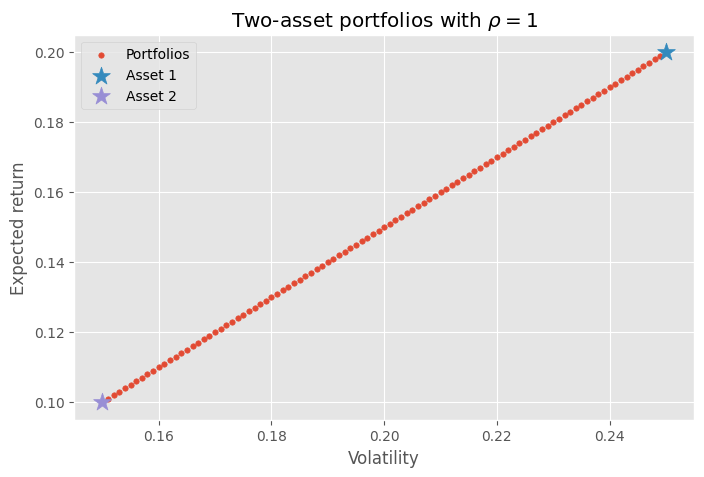

In [ ]:
# Generate portfolios with different weights
weights_1 = np.linspace(0, 1, 101)

returns_rho1 = []
vols_rho1 = []

for w1_i in weights_1:
    w2_i = 1 - w1_i

    returns_rho1.append(
        calc_portfolio_return(w1_i, w2_i, ret1, ret2)
    )
    vols_rho1.append(
        calc_portfolio_std(w1_i, w2_i, std1, std2, rho)
    )

plt.figure(figsize=(8, 5))
plt.scatter(vols_rho1, returns_rho1, s=15, label="Portfolios")
plt.scatter(std1, ret1, marker="*", s=180, label="Asset 1")
plt.scatter(std2, ret2, marker="*", s=180, label="Asset 2")

plt.xlabel("Volatility")
plt.ylabel("Expected return")
plt.title(r"Two-asset portfolios with $\rho=1$")
plt.legend()
plt.show()

### Interpretation

With perfect positive correlation, all portfolios lie on a straight line between the two assets.

There is no additional risk reduction from combining the assets.

The only thing we are doing is moving from one asset to the other by changing the weights.

# 5. What if correlation is lower?

Now we keep **everything else unchanged** and modify only the correlation.

This is the central experiment of the notebook.

### Exercise 3 — Compare three correlations

Calculate the volatility of the same 40%-60% portfolio for:

- $\rho=1$
- $\rho=0$
- $\rho=-0.5$

Before running the code, predict:

> Which portfolio should have the lowest volatility?

In [ ]:
# EXERCISE 3
correlations = [1, 0, -0.5]

for c in correlations:
  print(f"For a rho of {c}, the volatility is: {calc_portfolio_std(w1,w2,std1,std2,c):.3f}%")


For a rho of 1, the volatility is: 0.190%
For a rho of 0, the volatility is: 0.135%
For a rho of -0.5, the volatility is: 0.095%


### Main lesson

Notice something important:

- The assets are the same.
- Their expected returns are the same.
- Their individual volatilities are the same.
- The portfolio weights are the same.

Only **correlation** changed.

Yet portfolio volatility changed.

That is the diversification effect.

# 6. Case 2: Perfect negative correlation

Now let:

$$
\rho_{12}=-1
$$

The two assets move perfectly in opposite directions.

This is the strongest possible diversification case.

Portfolio volatility becomes:

$$
\sigma_P=
|w_1\sigma_1-w_2\sigma_2|
$$

For one particular combination of weights, portfolio volatility can even become zero.

### Exercise — Portfolios with Perfect Negative Correlation
Assume that the correlation between the two assets is:
$\rho_{12}=-1$
Generate 100 different portfolios by varying the weight of Asset 1 from 0 to 1. For each portfolio:
- calculate the weight of Asset 2;
- calculate the expected portfolio return;
- calculate the portfolio volatility.
Then plot the 100 portfolios in the return-volatility plane and include the two individual assets in the same figure.
Question: What do you observe about portfolio risk when the two assets are perfectly negatively correlated?

In [ ]:
peso1 = np.linspace(0,1,100)
peso2 = 1- peso1
rho = -1


expects = peso1 * ret1 + peso2 * ret2
volatility = calc_portfolio_std(peso1,peso2,std1,std2,rho)

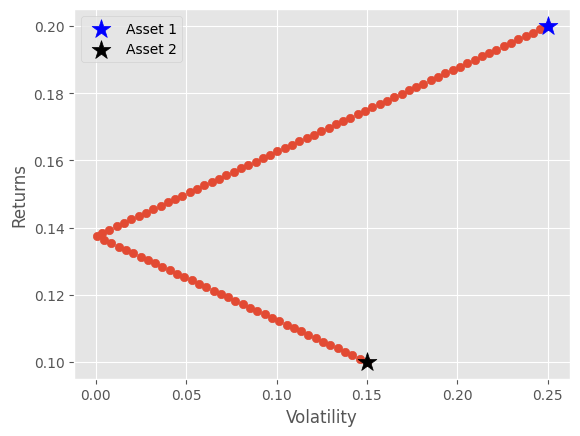

In [ ]:
plt.scatter(volatility,expects)
plt.scatter(std1,ret1,color = "blue", marker = "*",label = "Asset 1", s = 200)
plt.scatter(std2,ret2,color = "black", marker = "*",label = "Asset 2", s = 200)
plt.xlabel("Volatility")
plt.ylabel("Returns")
plt.legend()
plt.show()

### Exercise 4 — Find the zero-volatility portfolio

For $\rho=-1$, the minimum-volatility weight of asset 1 is:

$$
w_1=\frac{\sigma_2}{\sigma_1+\sigma_2}
$$

1. Calculate $w_1$.
2. Calculate $w_2$.
3. Calculate the portfolio expected return.
4. Verify that portfolio volatility is zero.

In [ ]:
# EXERCISE 4

w1_min = std1 / (std1 + std2)
w2_min = std2 / (std1 + std2)

ret_min = calc_portfolio_return(w1_min,w2_min,ret1,ret2)
vol_min = calc_portfolio_std(w1_min,w2_min,std1,std2,rho)

print(f"Weight asset 1: {w1_min:.2%}")
print(f"Weight asset 2: {w2_min:.2%}")
print(f"Portfolio return: {ret_min:.2%}")
print(f"Portfolio volatility: {vol_min:.2%}")

Weight asset 1: 62.50%
Weight asset 2: 37.50%
Portfolio return: 16.25%
Portfolio volatility: 10.00%


# 7. Compare several correlations

Now we can see the full picture.

We will calculate the portfolio opportunity set for several correlation values:

$$
\rho \in \{-1,-0.8,-0.5,0,0.5,1\}
$$

Before running the next cell, answer:

> **What do you expect to happen to portfolio risk as correlation decreases?**

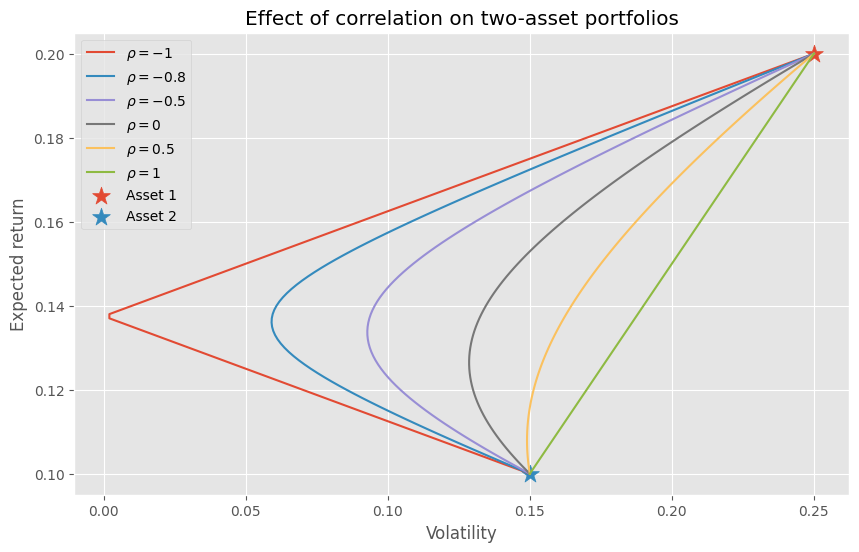

In [ ]:
correlation_values = [-1, -0.8, -0.5, 0, 0.5, 1]

plt.figure(figsize=(10, 6))

for rho_i in correlation_values:
    portfolio_returns = []
    portfolio_vols = []

    for w1_i in weights_1:
        w2_i = 1 - w1_i

        portfolio_returns.append(
            calc_portfolio_return(w1_i, w2_i, ret1, ret2)
        )
        portfolio_vols.append(
            calc_portfolio_std(w1_i, w2_i, std1, std2, rho_i)
        )

    plt.plot(
        portfolio_vols,
        portfolio_returns,
        label=fr"$\rho={rho_i}$"
    )

plt.scatter(std1, ret1, marker="*", s=180, label="Asset 1")
plt.scatter(std2, ret2, marker="*", s=180, label="Asset 2")

plt.xlabel("Volatility")
plt.ylabel("Expected return")
plt.title("Effect of correlation on two-asset portfolios")
plt.legend()
plt.show()

### Exercise 5 — Interpret the figure

Answer in words:

1. Which correlation produces the greatest diversification benefit?
2. Which correlation produces no diversification benefit?
3. Does changing correlation change the expected return of a portfolio with fixed weights?
4. Why does the set of portfolios move to the left when correlation decreases?

**Key concept:** moving to the left means achieving the same expected return with less volatility.

# 8. The minimum-volatility portfolio

For any correlation between the two assets, the weight of asset 1 in the minimum-variance portfolio is:

$$
w_1^*=
\frac{
\sigma_2^2-\rho_{12}\sigma_1\sigma_2
}{
\sigma_1^2+\sigma_2^2-2\rho_{12}\sigma_1\sigma_2
}
$$

and:

$$
w_2^*=1-w_1^*
$$

This formula identifies the leftmost point of each portfolio curve.

In [ ]:
def min_variance_weights(std1, std2, rho):
    w1 = (std2**2 - rho * std1 * std2) / (
        std1**2 + std2**2 - 2 * rho * std1 * std2
    )
    w2 = 1 - w1
    return w1, w2

### Exercise 6 — Minimum volatility and correlation

Calculate the minimum-volatility portfolio for:

- $\rho=0.8$
- $\rho=0$
- $\rho=-0.5$

For each case, report:

- $w_1$
- $w_2$
- expected return
- volatility

Then answer:

> How does lower correlation affect the minimum achievable portfolio volatility?

In [ ]:
# EXERCISE 6

for rho_i in [0.8, 0, -0.5]:
    w1_i, w2_i = min_variance_weights(std1, std2, rho_i)

    ret_i = calc_portfolio_return(w1_i, w2_i, ret1, ret2)
    vol_i = calc_portfolio_std(w1_i, w2_i, std1, std2, rho_i)

    print(f"\nrho = {rho_i}")
    print(f"w1 = {w1_i:.2%}")
    print(f"w2 = {w2_i:.2%}")
    print(f"return = {ret_i:.2%}")
    print(f"volatility = {vol_i:.2%}")


rho = 0.8
w1 = -30.00%
w2 = 130.00%
return = 7.00%
volatility = 14.23%

rho = 0
w1 = 26.47%
w2 = 73.53%
return = 12.65%
volatility = 12.86%

rho = -0.5
w1 = 33.67%
w2 = 66.33%
return = 13.37%
volatility = 9.28%


---

# 11. Calculate portfolio statistics from daily log returns

We previously calculated portfolio volatility from asset volatilities and correlation. An alternative is to construct the portfolio's **daily return series** and then calculate its mean and standard deviation.

For fixed weights, the weighted combination

$$\widetilde r_{P,t}=w_1r_{1,t}+w_2r_{2,t}$$



# 9. From theory to data

So far, correlation was an input chosen by us.

Now we will estimate correlation from return data.

The original course material includes datasets designed to illustrate different dependence patterns. We will use one of them to connect the theoretical formulas with observed returns.

In [ ]:
# Positive-correlation example
url_pos = (
    "https://raw.githubusercontent.com/alfonso-santos/"
    "microcredencial-carteras-python/refs/heads/Feb-2025/"
    "Tema_1_Activos_Intro/data/precios_corr_pos.csv"
)

prices_pos = pd.read_csv(url_pos, index_col=0, parse_dates=True)
prices_pos.columns = ["Asset 1", "Asset 2"]

returns_pos = np.log(prices_pos).diff().dropna()

print("Estimated correlation:")
print(returns_pos.corr())

prices_pos.head()

Estimated correlation:
         Asset 1  Asset 2
Asset 1  1.00000  0.98014
Asset 2  0.98014  1.00000


,Asset 1,Asset 2
2010-01-04,117.000000,158.000000
2010-01-05,113.192375,156.263037
2010-01-06,111.121152,155.307702
2010-01-07,107.084666,153.467719
2010-01-08,105.076790,152.540900


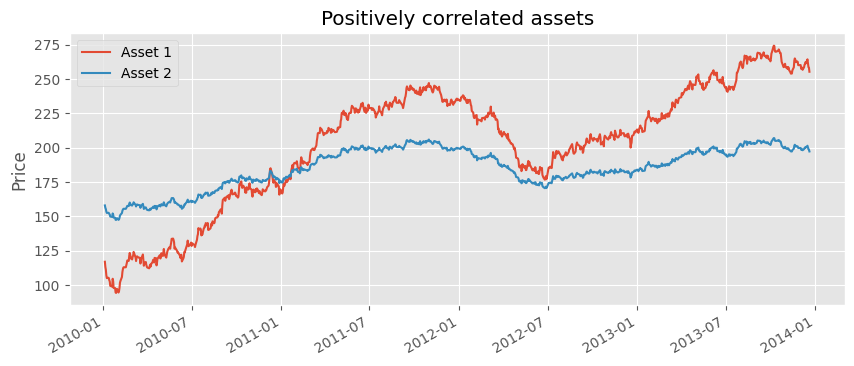

In [ ]:
# Visualize the two price series
prices_pos.plot(figsize=(10, 4), title="Positively correlated assets")
plt.ylabel("Price")
plt.show()

### Exercise 7 — Estimate correlation from data

Using `returns_pos`:

1. Calculate the correlation between Asset 1 and Asset 2.
2. Calculate the mean return and volatility of each asset.
3. Create a 50%-50% portfolio.
4. Calculate its mean return and volatility.
5. Compare portfolio volatility with the volatility of the two individual assets.

In [ ]:
# EXERCISE 7

rho_data = returns_pos.corr()

mean_returns = returns_pos.mean()
volatilities = returns_pos.std()

weights = np.array([0.5, 0.5])

portfolio_returns = mean_returns * weights

print("Correlation:", rho_data)
print("\nMean returns:")
print(mean_returns)

print("\nVolatilities:")
print(volatilities)

print("\n50%-50% portfolio")
print("Mean return:", mean_returns)
print("Volatility:", volatilities)

Correlation:          Asset 1  Asset 2
Asset 1  1.00000  0.98014
Asset 2  0.98014  1.00000

Mean returns:
Asset 1    0.000781
Asset 2    0.000222
dtype: float64

Volatilities:
Asset 1    0.011965
Asset 2    0.005326
dtype: float64

50%-50% portfolio
Mean return: Asset 1    0.000781
Asset 2    0.000222
dtype: float64
Volatility: Asset 1    0.011965
Asset 2    0.005326
dtype: float64


# 10. Final challenge — Build your own two-asset portfolio

Choose two stocks and download their daily Adjusted Close prices.

Suggested period:

**January 1, 2022 to January 1, 2026**

Then:

1. Calculate daily log returns.
2. Calculate the correlation between the two stocks.
3. Calculate the annualized return and volatility of each stock.
4. Generate 101 portfolios by varying the weight of stock 1 from 0% to 100%.
5. Plot all portfolios in the return-volatility plane.
6. Identify the minimum-volatility portfolio.
7. Explain whether diversification is important for this pair of stocks.

### Final question

> If you wanted stronger diversification, would you look for two assets with higher or lower correlation? Why?

In [ ]:
# FINAL CHALLENGE

import yfinance as yf

tickers = ["META", "CC"]  # Replace with your chosen assets

data = yf.download(
    tickers,
    start="2022-01-01",
    end="2026-01-01",
    auto_adjust=False,
    progress=False
)["Adj Close"]

returns = np.log(data).diff().dropna()

returns.head()

Ticker,CC,META
Date,,
2022-01-04,0.046547,-0.005955
2022-01-05,-0.011861,-0.037419
2022-01-06,0.013824,0.025252
2022-01-07,0.009481,-0.002017
2022-01-10,-0.027006,-0.011275


In [ ]:
ret_corr = returns.corr()
mean_ret = returns.mean() * 252
vol_ret = returns.std() *np.sqrt(252)

In [ ]:
w1_port = np.linspace(0,1,101)
w2_port = 1- w1_port

In [ ]:
expects = w1_port * mean_ret.iloc[0] + w2_port * mean_ret.iloc[1]
vol_port = np.sqrt(w1_port**2 * vol_ret.iloc[0]**2 + w2_port** 2 * vol_ret.iloc[1]**2+ 2* w1_port * w2_port *vol_ret.iloc[0] * vol_ret.iloc[1] * ret_corr.iloc[0,1])

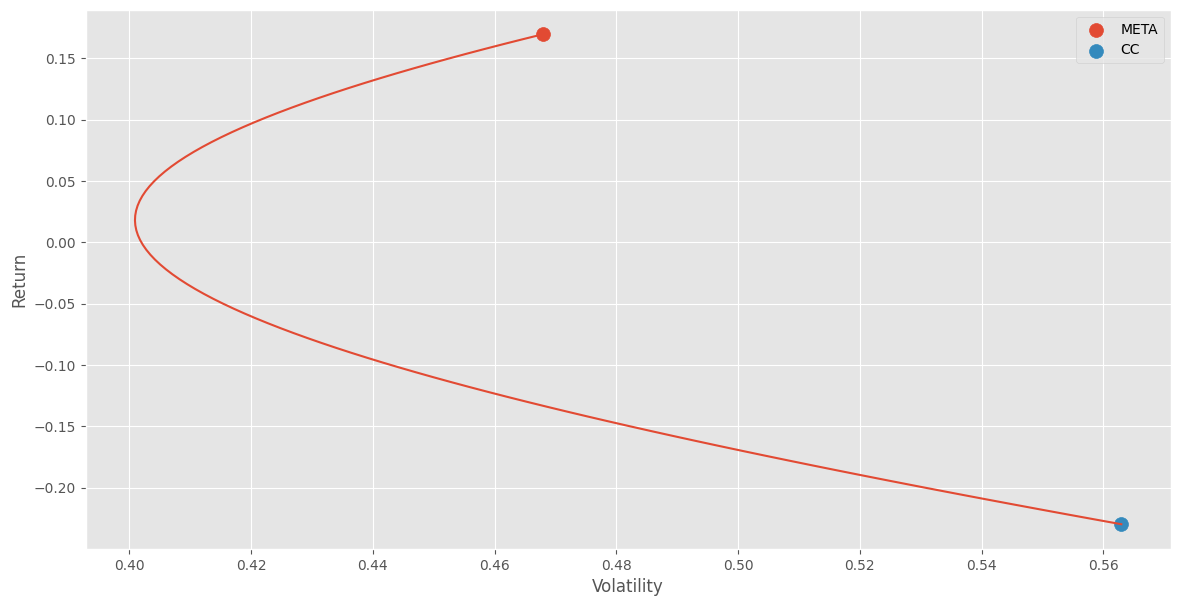

In [ ]:
plt.figure(figsize=(14,7))

plt.plot(vol_port,expects)
plt.scatter(vol_ret.iloc[1],mean_ret.iloc[1],s = 100, label = returns.columns[1])
plt.scatter(vol_ret.iloc[0],mean_ret.iloc[0],s = 100,label = returns.columns[0])
plt.legend()
plt.xlabel("Volatility")
plt.ylabel("Return")
plt.show()

# Summary

The main lesson of this notebook is:

> **Diversification does not come simply from owning more assets. It comes from combining assets that do not move perfectly together.**

Remember:

1. Portfolio expected return is a weighted average of asset expected returns.
2. Portfolio risk depends on asset volatilities **and correlation**.
3. Lower correlation generally creates greater diversification benefits.
4. With $\rho=1$, there is no diversification benefit.
5. With $\rho=-1$, diversification can theoretically eliminate volatility for a particular combination of weights.

---

# 11. Calculate portfolio statistics from daily log returns

We previously calculated portfolio volatility from asset volatilities and correlation. An alternative is to construct the portfolio's **daily return series** and then calculate its mean and standard deviation.

For fixed weights, the weighted combination

$$\widetilde r_{P,t}=w_1r_{1,t}+w_2r_{2,t}$$



In [ ]:
# Use the daily log returns already calculated earlier
returns_log = returns_pos.copy()

display(returns_log.head())
print("Dimensions:", returns_log.shape)


,Asset 1,Asset 2
2010-01-05,-0.033085,-0.011054
2010-01-06,-0.018468,-0.006132
2010-01-07,-0.037001,-0.011918
2010-01-08,-0.018928,-0.006057
2010-01-11,0.003051,0.000796


Dimensions: (999, 2)


### Calculate the same portfolio in two ways

Use a **40%-60% portfolio**. First calculate its mean log return and volatility from the two assets' statistics and correlation. Then calculate its daily **weighted log returns** and apply `.mean()` and `.std()`.

**Question:** Do the two methods give the same results (up to rounding)? Why?


In [ ]:
# Method A: Calculate statistics using the portfolio formulas
w = np.array([0.4, 0.6])
mu = returns_log.mean()
sd = returns_log.std()
rho = returns_log.corr().iloc[0, 1]

mean_formula = calc_portfolio_return(w[0], w[1], mu.iloc[0], mu.iloc[1])
std_formula = calc_portfolio_std(w[0], w[1], sd.iloc[0], sd.iloc[1], rho)


In [ ]:
# Method B: Calculate the weighted daily log-return series
portfolio_daily = returns_log @ w
mean_daily = portfolio_daily.mean()
std_daily = portfolio_daily.std()

# Plot daily returns
plt.figure(figsize=(12, 5))

plt.plot(portfolio_daily.index, portfolio_daily)

plt.title("Daily Portfolio Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.grid(True, alpha=0.3)

plt.show()



In [ ]:

print(f"Mean: formula = {mean_formula:.6f}, daily series = {mean_daily:.6f}")
print(f"Volatility: formula = {std_formula:.6f}, daily series = {std_daily:.6f}")

Mean: formula = 0.000446, daily series = 0.000446
Volatility: formula = 0.007944, daily series = 0.007944


## 12. Generate 1,000 random two-asset portfolios

Generate a **1,000 × 2** matrix of random weights and normalize each row to sum to 1.

Use matrix multiplication to calculate the **weighted daily log-return series** for all 1,000 portfolios:

$$\underbrace{R}_{T\times2}\;\underbrace{W^\top}_{2\times1000}=\underbrace{\widetilde R_P}_{T\times1000}$$

Here $R$ contains the two stocks' daily log returns. Each output column corresponds to one portfolio.


In [ ]:
# Generate 1,000 random long-only portfolios
rng = np.random.default_rng(42)
weights_random = rng.random((1000, 2))
weights_random = weights_random / weights_random.sum(axis=1, keepdims=True)

print("Weights shape:", weights_random.shape)
print("First five portfolios:\n", weights_random[:5])
print("Do all rows sum to 1?", np.allclose(weights_random.sum(axis=1), 1))


Weights shape: (1000, 2)
First five portfolios:
 [[0.63813823 0.36186177]
 [0.55181022 0.44818978]
 [0.08803269 0.91196731]
 [0.49194528 0.50805472]
 [0.22145847 0.77854153]]
Do all rows sum to 1? True


### Exercise 9 — Use matrix multiplication

Using the **daily log returns** and random weights:

1. Calculate all 1,000 weighted daily portfolio log-return series in one operation.
2. Calculate each portfolio's mean log return and volatility.
3. Plot the return–volatility diagram, including the two individual stocks.

**Check:** If there are $T$ dates, what are the dimensions of the result?


Portfolio daily log-return matrix shape: (999, 1000)


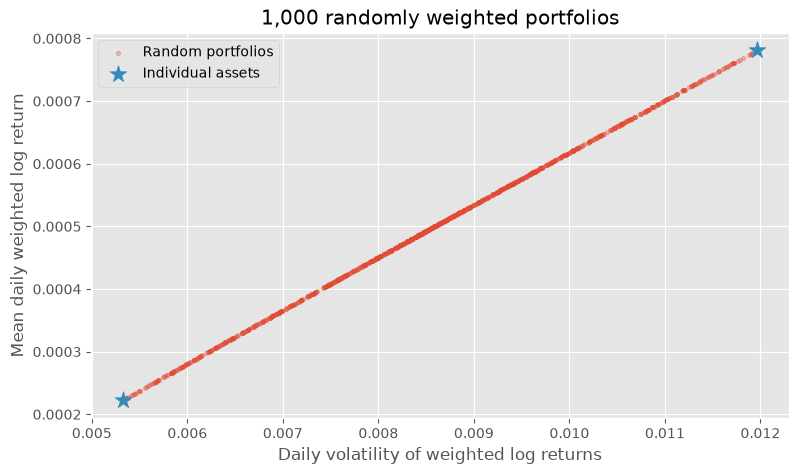

In [ ]:




print("Portfolio daily log-return matrix shape:", random_portfolio_returns.shape)

plt.figure(figsize=(9, 5))
plt.scatter(random_vols, random_means, s=10, alpha=0.35, label="Random portfolios")
plt.scatter(sd, mu, marker="*", s=160, label="Individual assets")
plt.xlabel("Daily volatility of weighted log returns")
plt.ylabel("Mean daily weighted log return")
plt.title("1,000 randomly weighted portfolios")
plt.legend()
plt.show()


### Exercise 10 — Find the least volatile random portfolio

Find the row of `weights_random` corresponding to the smallest value in `random_vols`.

**Question:** Why can the best random portfolio differ slightly from the exact minimum-volatility portfolio?

Best random weights: [0.00131355 0.99868645]
Lowest random portfolio volatility: 0.5334%


## 13. Do risk and correlation change over time?

So far we have estimated one volatility and one correlation for the full sample. Both can change over time.

A **63-trading-day rolling window** uses the 63 most recent daily log returns. The first 62 dates do not have a full window.


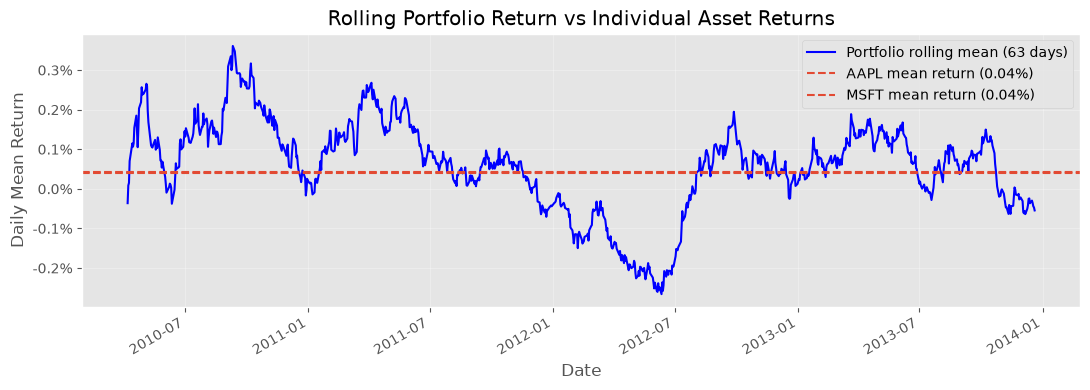

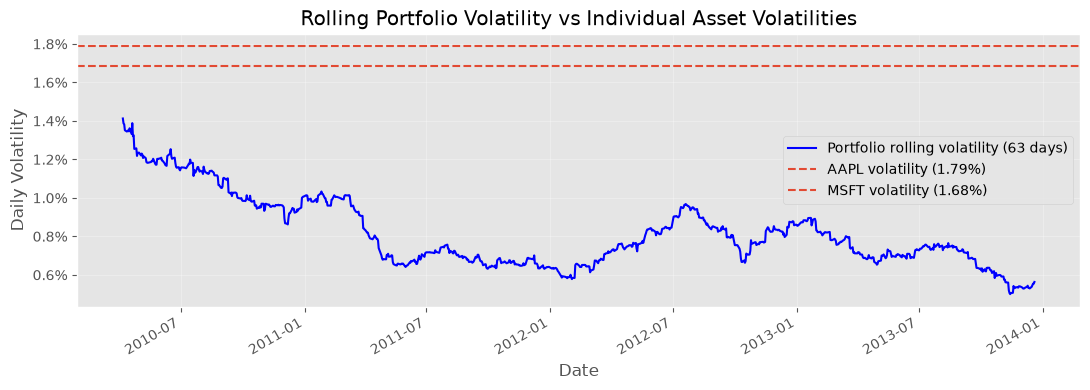

In [ ]:
# Calculate rolling statistics of the 50%-50% portfolio
rolling_mean = portfolio_50.rolling(window=window).mean()
rolling_std = portfolio_50.rolling(window=window).std()

# Calculate full-period statistics for the individual assets
asset_means = returns.mean()
asset_stds = returns.std()


# FIGURE 1: Rolling portfolio return vs individual asset mean returns
fig, ax = plt.subplots(figsize=(11, 4))

rolling_mean.plot(ax=ax, color="blue",
                  label=f"Portfolio rolling mean ({window} days)")

for ticker in tickers:
    ax.axhline(asset_means[ticker], linestyle="--",
               label=f"{ticker} mean return ({asset_means[ticker]:.2%})")

ax.set_title("Rolling Portfolio Return vs Individual Asset Returns")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Mean Return")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# FIGURE 2: Rolling portfolio volatility vs individual asset volatilities
fig, ax = plt.subplots(figsize=(11, 4))

rolling_std.plot(ax=ax, color="blue",
                 label=f"Portfolio rolling volatility ({window} days)")

for ticker in tickers:
    ax.axhline(asset_stds[ticker], linestyle="--",
               label=f"{ticker} volatility ({asset_stds[ticker]:.2%})")

ax.set_title("Rolling Portfolio Volatility vs Individual Asset Volatilities")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Volatility")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Rolling Return and Volatility: Individual Assets vs Portfolio

Using the daily log returns of the two stocks and the **50%-50% portfolio**, perform the following analysis:

1. Calculate the **rolling mean return** of each stock and the portfolio using a 63-day window.
2. Plot the three rolling mean returns in the same figure.
3. Calculate the **rolling volatility** of each stock and the portfolio using the same window.
4. Plot the three rolling volatilities in a second figure.

**Questions:**

- How does the portfolio's rolling mean return compare with those of the individual stocks?
- Is the portfolio's rolling volatility always lower than the volatility of both stocks?
- Does the diversification benefit remain constant over time?

**Conclusion:** Explain how combining two assets affects portfolio return and risk, and why the benefits of diversification may change over time.

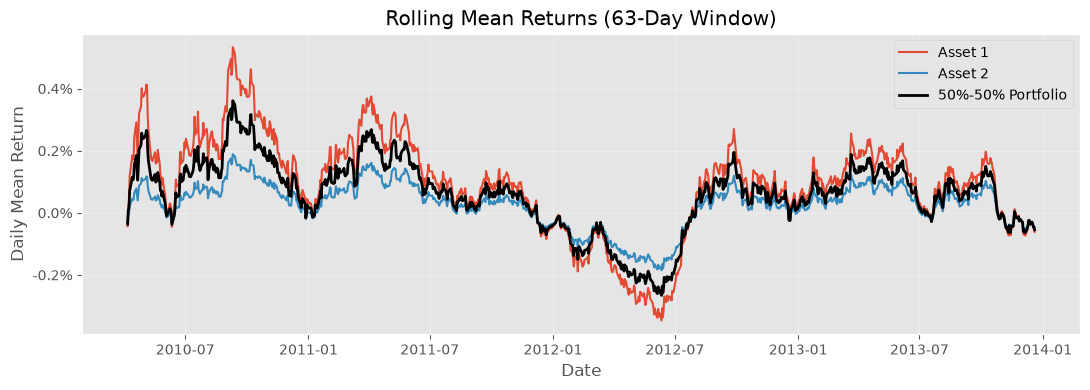

In [ ]:
# Define the rolling window
window = 63

# Calculate the daily returns of the 50%-50% portfolio
portfolio_50 = returns_log @ np.array([0.5, 0.5])

# Rolling statistics of individual assets
rolling_means = returns_log.rolling(window).mean()
rolling_stds = returns_log.rolling(window).std()

# Rolling statistics of the portfolio
rolling_mean_portfolio = portfolio_50.rolling(window).mean()
rolling_std_portfolio = portfolio_50.rolling(window).std()

# FIGURE 1: Rolling mean returns
fig, ax = plt.subplots(figsize=(11, 4))

for ticker in returns_log.columns:
    ax.plot(rolling_means.index, rolling_means[ticker], label=ticker)

ax.plot(
    rolling_mean_portfolio.index,
    rolling_mean_portfolio,
    color="black",
    linewidth=2,
    label="50%-50% Portfolio"
)

ax.set_title(f"Rolling Mean Returns ({window}-Day Window)")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Mean Return")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

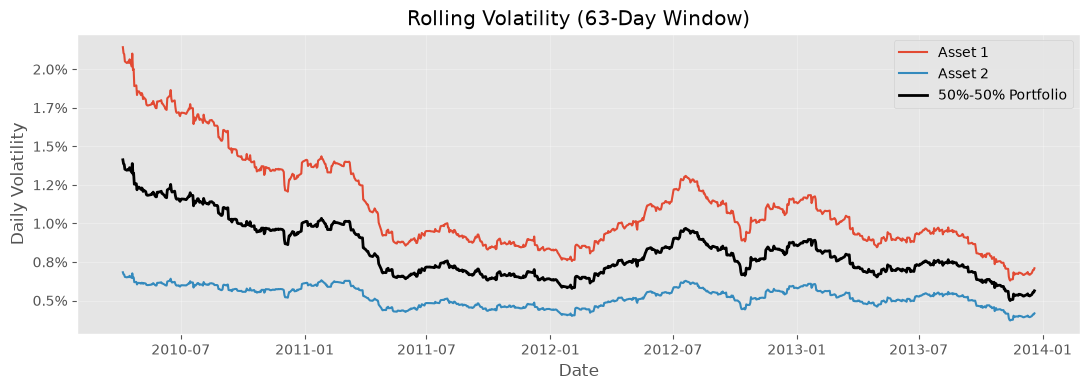

In [ ]:
# FIGURE 2: Rolling volatilities
fig, ax = plt.subplots(figsize=(11, 4))

# Rolling volatility of individual assets
for ticker in returns_log.columns:
    ax.plot(
        rolling_stds.index,
        rolling_stds[ticker],
        label=ticker
    )

# Rolling volatility of the 50%-50% portfolio
ax.plot(
    rolling_std_portfolio.index,
    rolling_std_portfolio,
    color="black",
    linewidth=2,
    label="50%-50% Portfolio"
)

# Format the figure
ax.set_title(f"Rolling Volatility ({window}-Day Window)")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Volatility")
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.1%}")
)

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 14. Rolling diversification gain

Calculate the portfolio's volatility from its **weighted daily log-return series**. Compare it with the volatility it would have if the stocks' log returns were perfectly positively correlated:

$$DG_t=1-\frac{\sigma_{P,t}}{0.5\sigma_{1,t}+0.5\sigma_{2,t}}$$

All three standard deviations use the **same 63-day window of daily log returns**. For example, $DG_t=0.20$ indicates a 20% reduction relative to the no-diversification benchmark for this weighted-log-return measure.


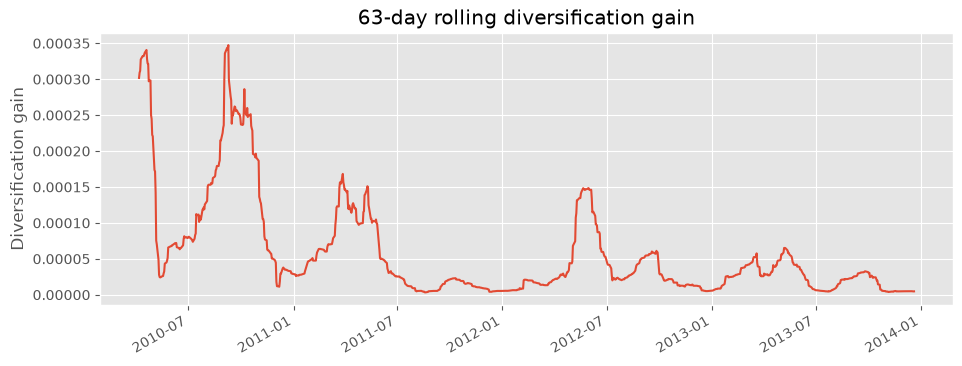

Mean DG: 0.01%
SD DG: 0.01%
Minimum DG: 0.00%
Score: 0.00%


In [ ]:
# Rolling volatility of the two stocks' daily log returns
stock_vol = returns_log.rolling(window).std()
no_diversification_vol = 0.5 * stock_vol.iloc[:, 0] + 0.5 * stock_vol.iloc[:, 1]

portfolio_rolling_vol = portfolio_50.rolling(window).std()
rolling_dg = 1 - portfolio_rolling_vol / no_diversification_vol

rolling_dg.plot(figsize=(11, 4), title="63-day rolling diversification gain")
plt.ylabel("Diversification gain")
plt.show()

mean_dg = rolling_dg.mean()
sd_dg = rolling_dg.std()
min_dg = rolling_dg.min()
score = mean_dg - 0.5 * sd_dg

print(f"Mean DG: {mean_dg:.2%}")
print(f"SD DG: {sd_dg:.2%}")
print(f"Minimum DG: {min_dg:.2%}")
print(f"Score: {score:.2%}")


### Exercise 12 — Stability versus average benefit

Suppose Pair A has average diversification gain of **30%** and standard deviation of **4%**. Pair B has average gain of **35%** and standard deviation of **20%**.

Calculate $Score=Mean(DG)-0.5\,SD(DG)$ for both pairs. Which wins? Explain why the average gain alone is not enough.

# S&P 500 Diversification Challenge — Find the Best Diversifying Pair

You are a portfolio analyst at an investment fund. Your task is to identify two stocks from the S&P 500 that, when combined in an equally weighted portfolio, provide the **largest and most stable diversification benefit**.

You will solve two problems: first, without any return requirement, and then with a minimum return constraint.

## Your objective

Find the eligible pair of stocks with the **highest diversification score** over **January 2, 2024 to December 31, 2025**, inclusive, using daily Adjusted Close prices adjusted for stock splits and dividends.

Each portfolio must contain two different stocks with fixed weights:

$$
w_1=w_2=0.5
$$

## Eligible stocks and data

Use the tickers in **Wikipedia's S&P 500 component stocks table**. Later changes to the list do not affect this competition.

Use the same stock universe and analysis period as in the previous Tail Risk Challenge.

The following rules apply:

- Download daily **Adjusted Close** prices and calculate daily logarithmic returns using
- A stock must have valid daily returns for at least **90% of US equity trading sessions** in the analysis period.

$$
\widetilde r_{P,t}=0.5r_{1,t}+0.5r_{2,t}
$$


- Use **63-day rolling windows** containing complete daily return observations.
- Use sample standard deviations (`ddof=1`) for volatility and for the variability of diversification gains.


## Step 1 — Calculate the diversification gain

For each eligible pair of stocks, calculate the diversification gain in each rolling window:

$$
DG_t=1-\frac{\sigma_{P,t}}{0.5\sigma_{1,t}+0.5\sigma_{2,t}}
$$

where:

- $\sigma_{P,t}$ is the volatility of the 50%-50% portfolio.
- $\sigma_{1,t}$ and $\sigma_{2,t}$ are the individual stock volatilities.

All volatilities must be calculated using daily log returns over the same 63-day window.

The denominator represents the portfolio volatility that would arise if the stocks were perfectly positively correlated.

Next, calculate:

$$
Score=\operatorname{Mean}(DG)-0.5\operatorname{SD}(DG)
$$

The score rewards a high average diversification gain and penalizes instability.

**Higher scores are better.**

Also calculate the minimum diversification gain observed across the rolling windows.

## Part A — Without a return constraint

Find the eligible pair of stocks that achieves the **highest diversification score**, regardless of its mean return.

Calculate the pair's annualized mean portfolio log return:

$$
\bar r_{P,ann}=252\operatorname{Mean}(r_{P,daily})
$$

## Part B — With a return constraint

Repeat the search, but now consider only pairs whose annualized mean log return is at least as high as that of the S&P 500 index over the same period.

The condition is:

$$
\bar r_{P,ann}\geq\bar r_{S\&P500,ann}
$$

Use `^GSPC` as the S&P 500 benchmark.

Both annualized mean log returns must be calculated using the same dates and the same methodology:

$$
\bar r_{ann}=252\operatorname{Mean}(r_{daily})
$$

Among all eligible pairs satisfying the return constraint, select the one with the **highest diversification score**.

## What to submit

For **each part**, report:

1. The two selected tickers, in alphabetical order, using the original Wikipedia symbols.
2. The annualized mean portfolio return (%).
3. The mean rolling diversification gain (%).
4. The standard deviation of the rolling diversification gain (%).
5. The minimum rolling diversification gain (%).
6. The final diversification score (%).

Plot both selected pairs' rolling diversification-gain series in the same figure.

Answer the following questions:

1. Did the return constraint change the selected pair?
2. Did the highest attainable diversification score decrease? Why?
3. Which selected pair has the more stable diversification gain?
4. Why is selecting the pair with the lowest full-sample correlation not necessarily equivalent to maximizing the diversification score?

**Important:** Briefly explain your selection method, how you aligned trading dates, how you handled missing observations, and how you calculated the rolling statistics. Brute-force search is allowed.

## Financial interpretation

The challenge illustrates that diversification depends on more than simply choosing two stocks with low correlation.

A good pair should provide a **large and stable reduction in portfolio volatility**. Imposing a minimum return requirement may also change which pairs are attractive.

The diversification score measures historical risk reduction relative to a hypothetical perfectly correlated portfolio. It does not guarantee that the same diversification benefit will persist in the future.

In [ ]:
# Download the S&P 500 component table.
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
response = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
response.raise_for_status()

# Preserve Wikipedia symbols and adapt them for Yahoo Finance.
wikipedia_tickers = pd.read_html(StringIO(response.text))[0]["Symbol"].tolist()
sp500_tickers = [ticker.replace(".", "-") for ticker in wikipedia_tickers]

sp500_tickers[:10]

['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']